In [2]:
#  Benjamin Wollant
#  March 11, 2024

#  This is a script for simulating single molecule kinetics via a Poisson Process for a nanoswitch consturct
#  

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.linalg import expm

In [3]:
#Functions for Simulation
#target concentration
def gen_target_array(steps, number_timepoints, time_step):
    target = np.zeros(number_timepoints)
    
    for s in steps:
        mode = s.size
        start = int(60*round(s[0]/time_step))
        stop = int(60*round(s[1]/time_step))  
        
        match mode:
            case 3: #step functions between times at indices 0 and 1, value of index 2
                target[start:stop] += s[2]
            case 4: #linear functions between times at indices 0 and 1, values ramp from index 2 to index 3 linearly
                slant = np.linspace(s[2], s[3], stop-start) # may need to ramp with logspace ???
                target[start:stop] += slant
    
    return target

def modified_gillespie(target, number_timepoints, time_step, initial_state: np.ndarray, rates: list): 
    n_switches = initial_state.size
    current_state = initial_state.copy()
    #0- A (unbound)
    #1- B (bound)
    
    kon = rates[0] # 1/(M*s)
    koff = rates[1]  # 1/s
  
    state_traces = np.zeros((n_switches,1+number_timepoints))
    state_traces[:,0] = current_state.copy()
    
    #Modified Gillespie Algorithm
    #   no variable timestep, just compute probability of transition at uniform time step and randomly sample
    for i in range(number_timepoints):
            
        for j in range(n_switches):
            r = np.random.rand()
            
            match current_state[j]:
                case 0: #if unbound 
                    p_B = kon*target[i]*time_step
                    if r < p_B:
                        current_state[j] = 1
        
                case 1: #if bound
                    p_A = koff*time_step
                    if r < p_A:
                        current_state[j] = 0     
            
        state_traces[:,i+1] = current_state
    return state_traces

def gen_ensembles(state_traces):
    switch_tracesA = (state_traces == 0).astype(int)
    switch_tracesB = (state_traces == 1).astype(int)

    ensemble_A = np.sum(switch_tracesA,0)
    ensemble_B = np.sum(switch_tracesB,0)
    
    return [ensemble_A, ensemble_B]

def plot_ensemble_traces(ensemble_A, ensemble_B, Target, t, n_switches):
    plt.figure(figsize=(10, 4))
    #plt.plot(t, ensemble_A[0:-1]/n_switches, color='#0000FF', label='unbound fraction')
    plt.plot(t/3600,ensemble_B[0:-1]/n_switches, color='#E50000', label='bound fraction')

    
    #plt.fill_between(t, -0.05*n_switches, 1.05*n_switches)
    
    #plt.title('Antibody Binding Kinetics')
    plt.xlabel('time (hours)')
    plt.ylabel('fraction of affinity reagens bound', color='black')
    plt.ylim([0,1.05])
    plt.legend(loc='upper left')
    plt.grid()
    
    
    ax2 = plt.gca().twinx()
    ax2.semilogy(t/3600, Target, label='Target', color='black')
    
    
    
    ax2.set_ylabel('target concentration (M)')
    
    #plt.legend(loc='center left')
    
    
    
    plt.show()
    
    
    return

def simulate(n, rates, duration, dt, T_array):
    num_timepoints = int(round(duration/dt))
    time = np.asarray(range(0,num_timepoints))*dt
    
    #Generate Target(t) and Magnet(t) arrays
    T = gen_target_array(T_array, num_timepoints, dt)

    #State Variables
    start_state = np.zeros(n)
    #0- A (unbound)
    #1- B1 (bound to Ab1)
    #2- B2 (bound to Ab2)
    #3- C (bound to Ab1 and Ab2)
    #4- D (two targets bound)

    switch_traces = modified_gillespie(T, num_timepoints, dt, start_state, rates)

    ensembleA, ensembleB = gen_ensembles(switch_traces)
    plot_ensemble_traces(ensembleA, ensembleB, T, time, n)
    
    return switch_traces

def first_order_model_k(t, a, b, k):
    return a * (1 - np.exp(-k*t)) + b

# Fit trace to first order model
def fit_first_order_k(a_guess, b_guess, k_guess, t_data, trace_data):
    p0 = [a_guess, b_guess, k_guess]
    params, covariance = curve_fit(first_order_model_k, t_data, trace_data, p0=p0)
    return params, covariance

def matrix_exponential_solution(T: float, kon: float, koff: float, x0: np.ndarray, dt: float, duration: float, fit_start: int):
    # Normalize x0
    x0 = x0/np.sum(x0)
    
    # Define the state transition matrix A
    A = np.array([
        [-kon*T, koff],
        [kon*T, -koff]
    ])
    
    # Time evolution
    num_timepoints = int(round(duration/dt))
    time = np.asarray(range(0,num_timepoints))*dt
    traces = np.array([expm(A*t) @ x0 for t in time])
    bound_frac = traces[:, 1]
    
    # # Fit with first order kinetics
    # a_guess = np.max(bound_frac)
    # k_guess = kon*T+koff
    # b_guess = x0[1]
    # params_k, covariance_k = fit_first_order_k(a_guess=a_guess, b_guess=b_guess, k_guess=k_guess, t_data=time[fit_start:], trace_data=bound_frac[fit_start:])
    # tau_fit_k = 1/params_k[2]
    
    
    return x0, time, traces #, tau_fit_k


def plot_matrix_exponential_fits(time: np.ndarray, traces: np.ndarray): 
    plt.figure(figsize=(8, 4))
    
    plt.plot(time, traces[:,0], label='fraction unbound', linewidth=2.5, color='#0000FF')
    plt.plot(time, traces[:,1], label='fraction bound', linewidth=2.5, color='#E50000')
    
    plt.title('first order binding kinetics for single binder')
    plt.xlabel('time (s)')
    plt.ylabel('state fraction', color='black')
    plt.legend(loc='upper right')
    plt.grid()
    plt.legend(loc='lower right')
    plt.ylim(0.00,1.01*max(traces[:,1]))
    plt.show()




        

In [4]:
n_switches = 1000
timestep = 0.5 #s

#For Nico's dAb switch...
#TNF-alpha:
#   kon1: 380402 (3.8e5)
#   koff1: 0.002475 (2.5e-3)
#   kon2: 138971 (1.4e5)
#   koff2: 0.002103 (2.1e-3)

#MCP-1:
#   kon1: 323431 (3.2e5)
#   koff1: 0.001650 (1.6e-3)
#   kon2: 401660 (4.0e5)
#   koff2: 0.00240 (2.4e-3)

kon = 1*10**5.5 # 1/(M*s)
koff = 6.3e-5 #1/s


rate_constants = [kon, koff]

#Step up, no space, 15 minute time steps
T_arr15 = np.asarray([[5,20, np.sqrt(10)*1e-11], [20, 35, 1e-10], [35,50, np.sqrt(10)*1e-10], [50, 65, 1e-9], [65,80, np.sqrt(10)*1e-9], [80, 95, 1e-8]] ) #input as minutes for time windows, code will convert to s 
M_arr15 = np.asarray([[15, 20], [30,35], [45,50], [60,65], [75,80], [90,95], [105,110]]) #input as minutes for time windows, code will convert to s

#Step up, no space, 30 minute time steps
T_arr30 = np.asarray([[5,35, np.sqrt(10)*1e-11], [35, 65, 1e-10], [65,95, np.sqrt(10)*1e-10], [95, 125, 1e-9], [125,155, np.sqrt(10)*1e-9], [155,185, 1e-8]] ) #input as minutes for time windows, code will convert to s 
M_arr30 = np.asarray([[25, 35], [55,65], [85,95], [115,125], [145,155], [175,185], [205, 215]]) #input as minutes for time windows, code will convert to s

#Step down, no space, 15 minute time steps
T_arr15_down = np.asarray([[5,20, 1e-8], [20, 35, np.sqrt(10)*1e-9], [35,50, 1e-9], [50, 65, np.sqrt(10)*1e-10], [65,80, 1e-10], [80, 95, np.sqrt(10)*1e-11]] ) #input as minutes for time windows, code will convert to s 

#Step down, no space, 30 minute time steps
T_arr30_down = np.asarray([[5,35, 1e-8], [35, 65, np.sqrt(10)*1e-9], [65,95, 1e-9], [95, 125, np.sqrt(10)*1e-10], [125,155, 1e-10], [155,185, np.sqrt(10)*1e-11]] ) #input as minutes for time windows, code will convert to s 

#Step from 20 to 500 pM and down
T_arr_20_500_20pM = np.asarray([[0,180, 20e-12], [180, 210, 500e-12], [210,600, 20e-12]] ) #input as minutes for time windows, code will convert to s 

#Step up, 60 minute time steps
T_arr60_space = np.asarray([[0, 60, np.sqrt(10)*1e-11], [60, 120, 1e-10], [120,180, np.sqrt(10)*1e-10], [180, 240, 1e-9], [240,300, np.sqrt(10)*1e-10], [300,360, 1e-10], [360, 420, np.sqrt(10)*1e-11]] ) #input as minutes for time windows, code will convert to s 

In [5]:
# kon_1 = 3.2e5 # 1/(M*s)
# kon_2 = 4.0e5 # 1/(M*s)
# koff_1 = 1.6e-3 #1/s
# koff_2 = 2.4e-3 #1/s
# C_eff = 100e-9 # M

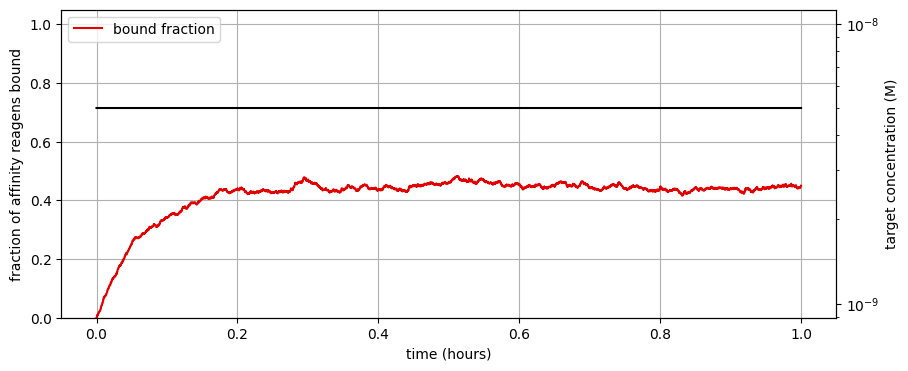

In [5]:
# single binder, two state simulation for one MCP-1 Ab
kon = 4.0e5# 1/(M*s)
koff = 2.4e-3 #1/s
rate_constants = [kon, koff]

traces = simulate(n_switches, rate_constants, 1*60*60, timestep, np.asarray([[0,60, 5e-9]])) #220*60 for 30 mins, 120*60 for 15 mins


0.0003
720000.0


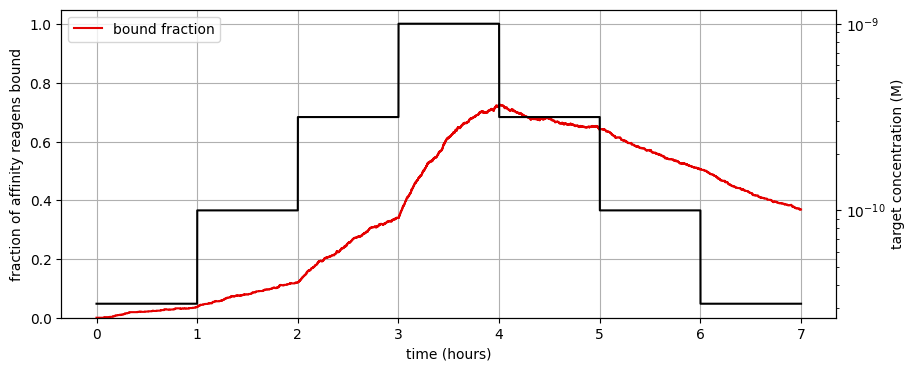

In [7]:
# single binder, two state simulation for one MCP-1 Ab
kon = 3.6e5# 1/(M*s)
koff = 2.4e-3 #1/s
Ceff = 100e-9 #M

koff_eff = 2*koff*(koff/(koff+Ceff*kon))
kon_eff = 2*kon
print(koff_eff)
print(kon_eff)
rate_constants = [4.0e5, 1e-4]

traces = simulate(n_switches, rate_constants, 7*60*60, timestep, T_arr60_space) #220*60 for 30 mins, 120*60 for 15 mins

In [56]:
koff_eff = 2*koff*(koff/(koff+10*Ceff*kon))
kon_eff = 2*kon
print(koff_eff)
print(kon_eff)
print(koff_eff/kon_eff)

5.753096284458649e-06
800000.0
7.191370355573312e-12


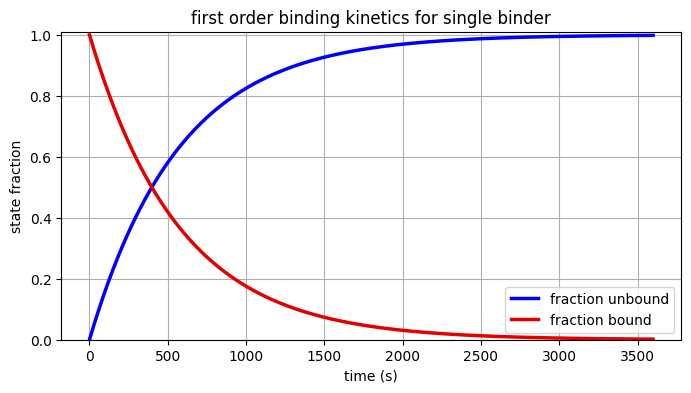

equilibrium fraction:  0.0


In [8]:
timestep=0.5
T = 0
kon = 1.2e7
koff = 1.74e-3
Kd = koff/kon
x0, time, traces = matrix_exponential_solution(T=T, kon=kon, koff= koff, x0=[0.0, 1.0], dt=timestep, duration=60 * 60 * 1, fit_start=5 * 60)

plot_matrix_exponential_fits(time=time, traces=traces)  #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)
equilibrium_fraction = T/(T+Kd)
print("equilibrium fraction: ", equilibrium_fraction )

In [78]:
9/(9+10)

0.47368421052631576

In [54]:
1.5e-3/3.0e5

5e-09

In [25]:
import numpy as np
import matplotlib.pyplot as plt

def generate_colored_circle_grid_triplet(n=10, frac_red=0.3, frac_green=0.3, frac_blue=0.4,
                                         radius=0.4, blackout_indices=None):
    assert abs(frac_red + frac_green + frac_blue - 1.0) < 1e-6, "Fractions must sum to 1"

    # Total number of circles
    total = n * n
    n_red = int(total * frac_red)
    n_green = int(total * frac_green)
    n_blue = total - n_red - n_green

    # Generate shuffled color list
    colors = ['red'] * n_red + ['green'] * n_green + ['blue'] * n_blue
    np.random.shuffle(colors)

    # Determine which indices are red or green (for blackout)
    blackout_set = set()
    for idx, color in enumerate(colors):
        if color in ['red', 'green']:
            blackout_set.add(idx)
    blackout_array = np.array(sorted(blackout_set))

    # Create three subplots
    fig, axes = plt.subplots(1, 3, figsize=(3 * n, n))
    views = ['All Opaque (Overlay Optional)', 'Subset Transparent', 'Black Boxes Over Subset']

    for ax, mode in zip(axes, views):
        ax.set_aspect('equal')
        ax.axis('off')

        for idx, color in enumerate(colors):
            row = idx // n
            col = idx % n
            x, y = col, n - 1 - row

            if mode == 'All Opaque (Overlay Optional)':
                ax.add_patch(plt.Circle((x, y), radius, color=color, alpha=1.0))
                if blackout_indices is not None and idx in blackout_indices:
                    ax.add_patch(plt.Rectangle((x - radius, y - radius), 2 * radius, 2 * radius, color='black'))

            elif mode == 'Subset Transparent':
                alpha = 0.3 if color in ['red', 'green'] else 1.0
                ax.add_patch(plt.Circle((x, y), radius, color=color, alpha=alpha))

            elif mode == 'Black Boxes Over Subset':
                if color in ['red', 'green']:
                    ax.add_patch(plt.Rectangle((x - radius, y - radius), 2 * radius, 2 * radius, color='black'))
                else:
                    ax.add_patch(plt.Circle((x, y), radius, color=color, alpha=1.0))

        ax.set_xlim(-0.5, n - 0.5)
        ax.set_ylim(-0.5, n - 0.5)
        # ax.set_title(mode)

    plt.tight_layout()
    plt.show()

    return blackout_array

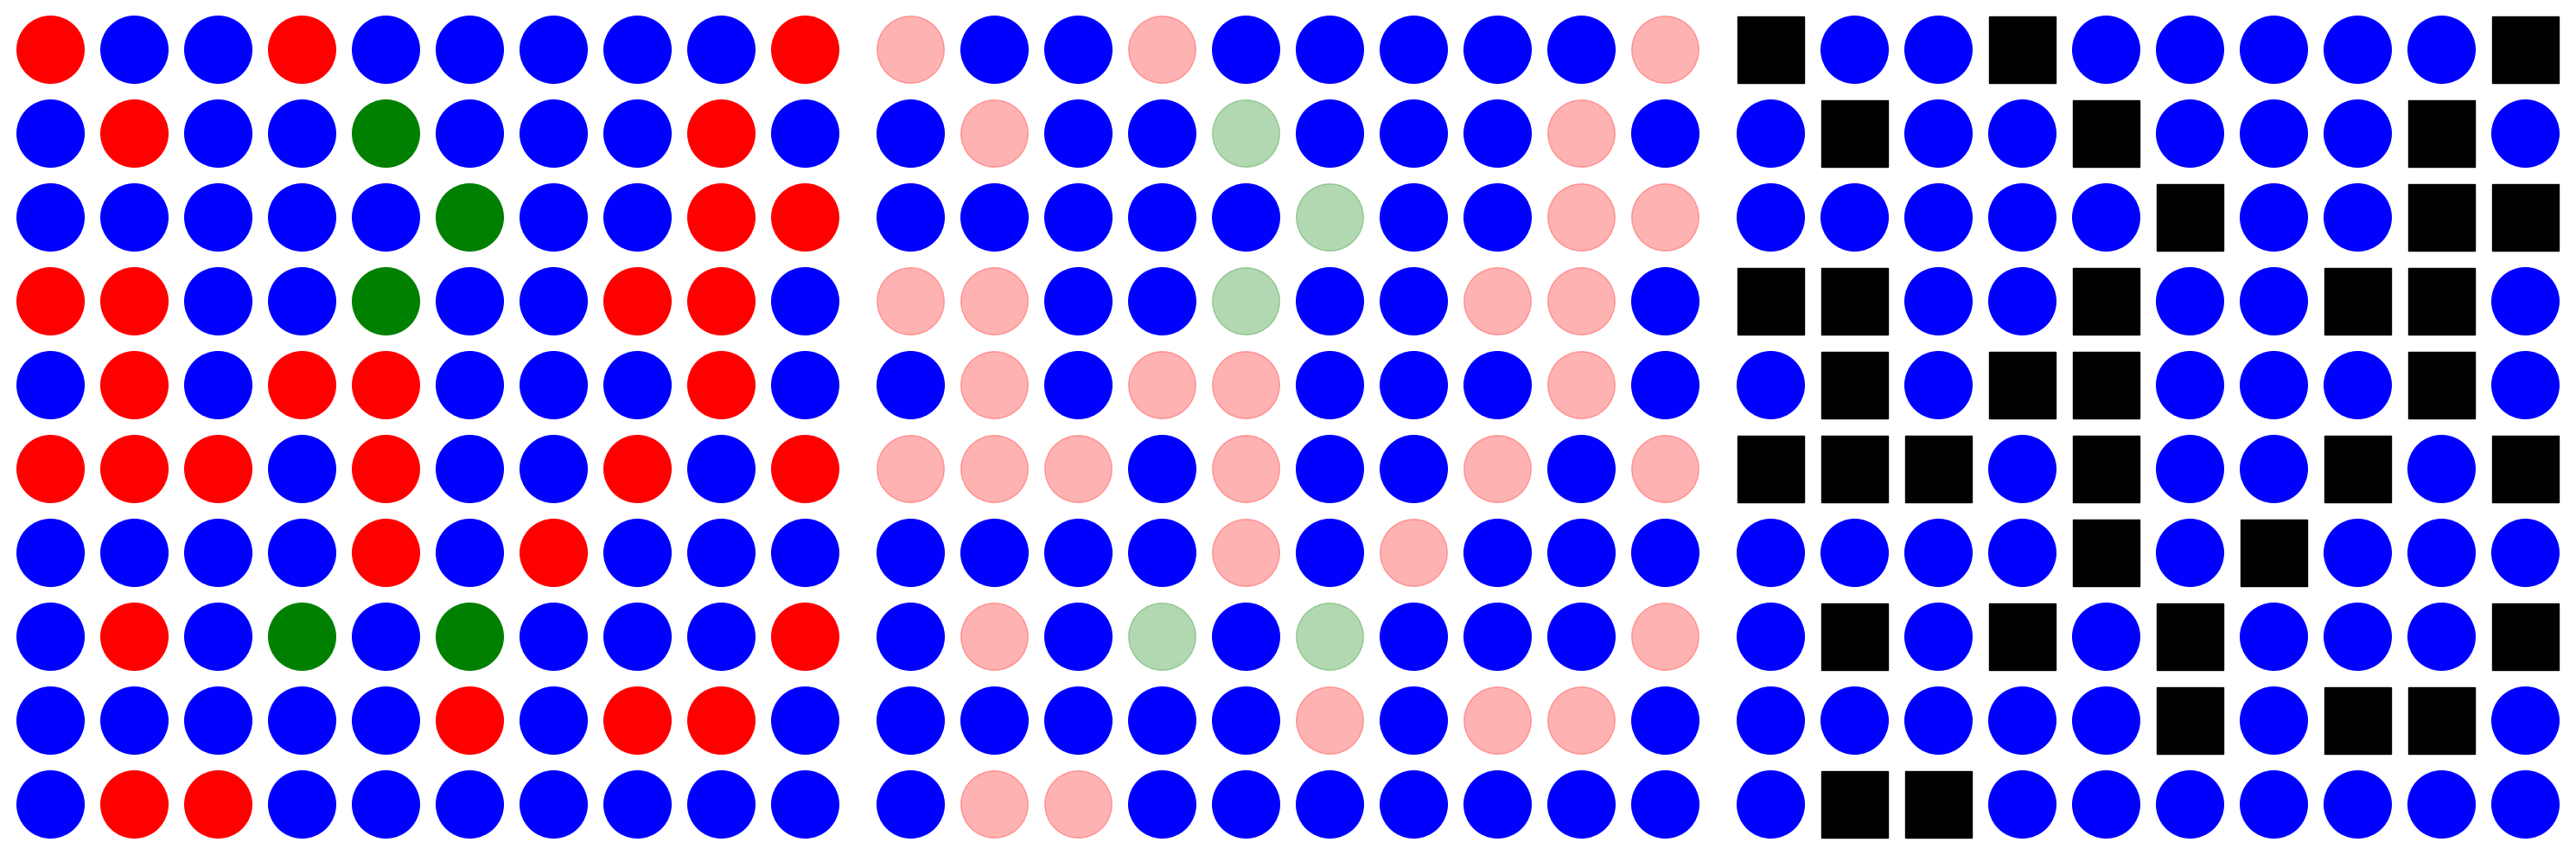

Blackout indices: [ 0  3  9 11 14 18 25 28 29 30 31 34 37 38 41 43 44 48 50 51 52 54 57 59
 64 66 71 73 75 79 85 87 88 91 92]


In [26]:

# Example usage
blackout_ids_1 = generate_colored_circle_grid_triplet(n=10, frac_red=0.3, frac_green=0.05, frac_blue=0.65)
print("Blackout indices:", blackout_ids_1)


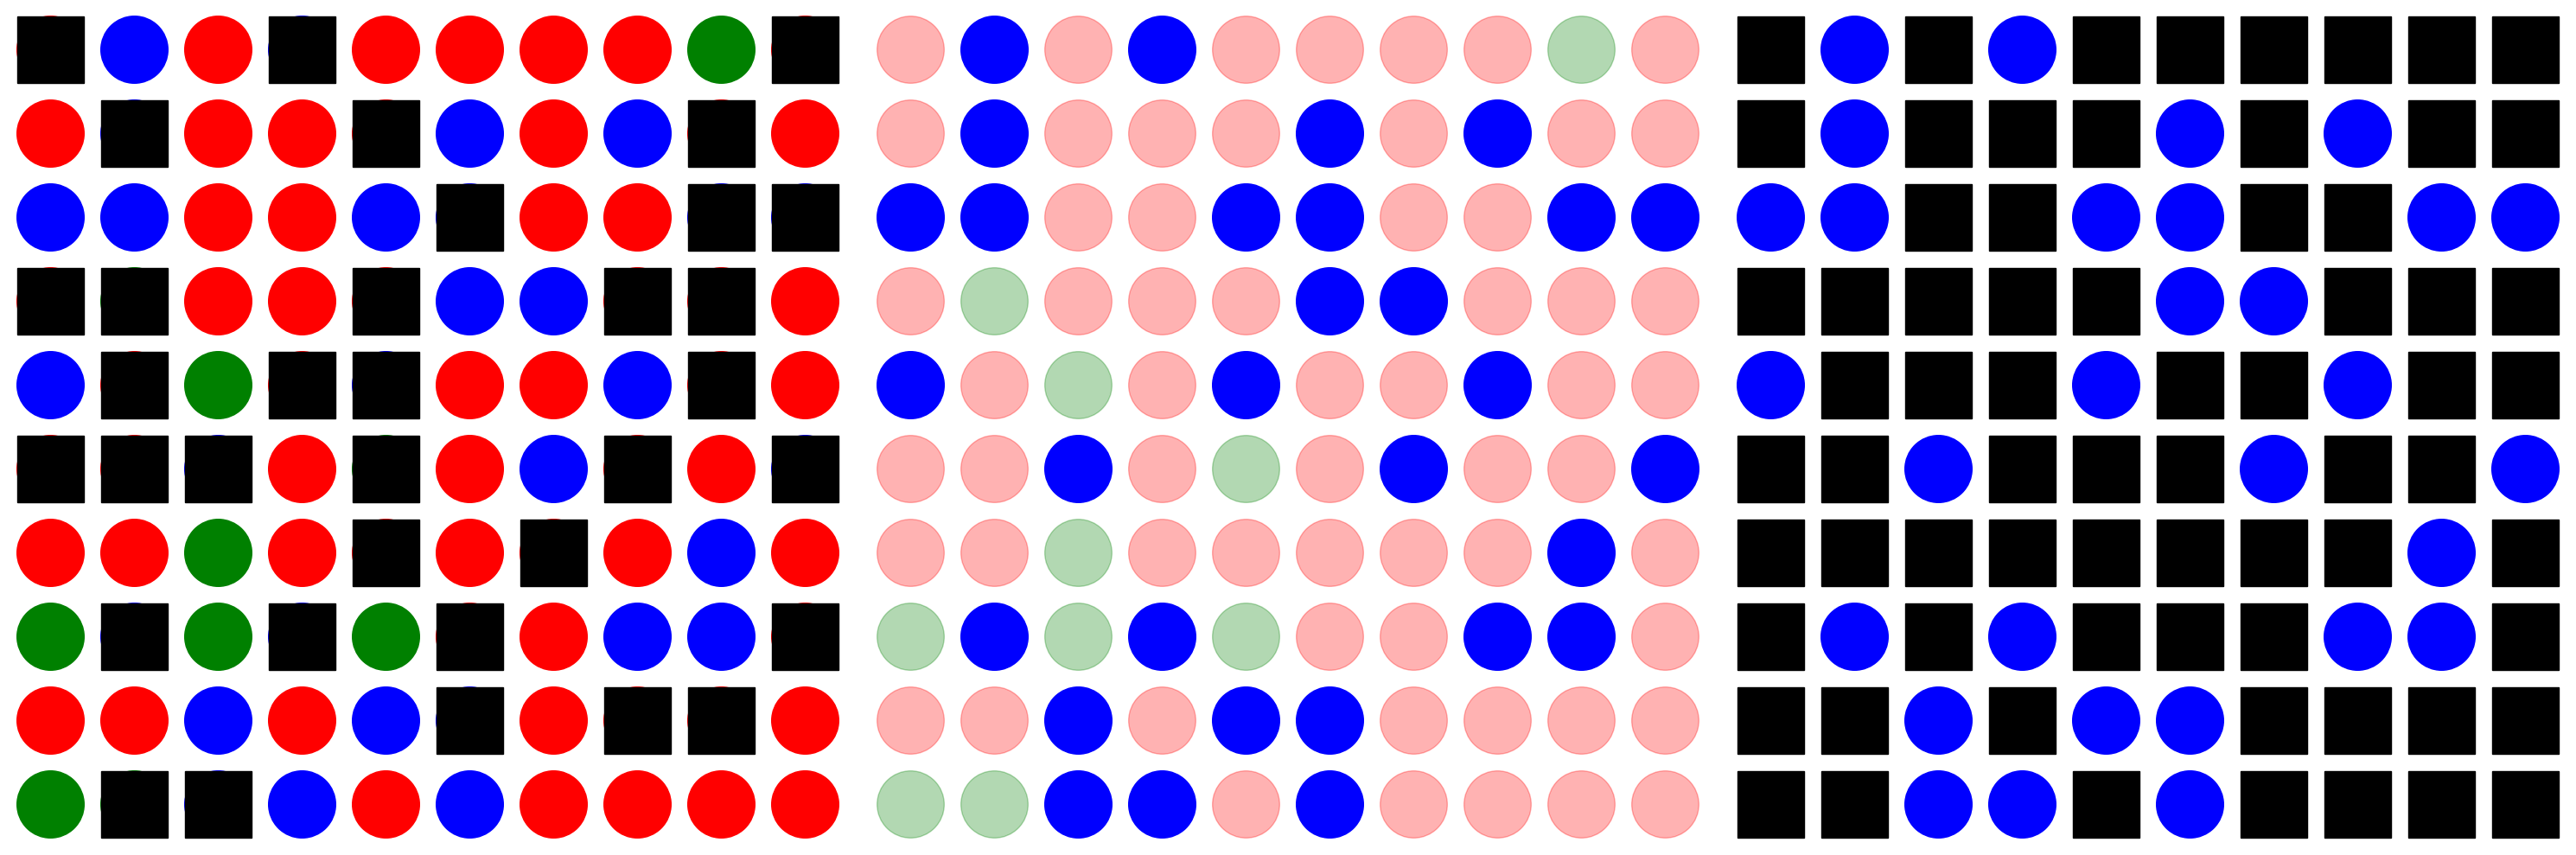

In [28]:
blackout_ids_2 = generate_colored_circle_grid_triplet(n=10, frac_red=0.6, frac_green=0.1, frac_blue=0.3, blackout_indices=blackout_ids_1)


In [29]:
len(blackout_ids_1)

35

In [30]:
40/65

0.6153846153846154